# Исследование рынка новых автомобилей в Казахстане (2019 г.)

## Анализ продаж и позиционирования компании "Mercur Auto"

Курсовой проект по дисциплине: **Предподготовка и анализ данных**

Выполнил студент: **Ильин А.В., группа М26-555**

---
---

### Содержание:
* [1. Введение и загрузка данных](#intro)
* [2. Очистка данных](#cleaning)
* [3. Исследовательский анализ (EDA)](#eda)
* [4. Анализ рынка и позиции Mercur Auto](#market)
* [5. Выводы и рекомендации](#conclusions)
* [6. Ссылка на очет и очищенный датасет](#link)

---
---

<a id="intro"></a>
## 1. Первичный осмотр данных

In [ ]:
# Импортируем библиотеки для работы с данными и таблицами
import calendar
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns


# Загружаем данные из датасета
file_path = '/content/autokz2019.csv'
df = pd.read_csv(file_path, sep=';', decimal=',')

# sep=',' - скорее всего, разделитель запятая. Если будет ошибка, попробуем ';'
# decimal='.' - десятичный разделитель точка

In [ ]:
# Смотрим на первые строки, чтобы понять структуру
print("--- Первые 5 строк ---")
display(df.head())

# Смотрим общую информацию: типы данных, количество непустых значений
print("\n--- Общая информация ---")
df.info()

# Смотрим размер таблицы
print(f"\nРазмер таблицы: {df.shape[0]} строк и {df.shape[1]} столбцов")

# Смотрим на пропуски в процентном соотношении (очень наглядно)
print("\n--- Процент пропусков по столбцам ---")
missing_percent = df.isnull().sum() / len(df) * 100
print(missing_percent[missing_percent > 0].sort_values(ascending=False).round(2))

--- Первые 5 строк ---


,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",...,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,наличный,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
3,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,безналичный,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
4,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,наличный,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт



--- Общая информация ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Год                             39966 non-null  int64  
 1   Месяц                           39966 non-null  object 
 2   Компания                        39966 non-null  object 
 3   Бренд                           39966 non-null  object 
 4   Модель                          39966 non-null  object 
 5   Модификация                     36375 non-null  object 
 6   Год выпуска                     39465 non-null  object 
 7   Страна-производитель            39966 non-null  object 
 8   Вид топлива                     36826 non-null  object 
 9   Объём двиг, л,                  35708 non-null  object 
 10  Коробка передач                 36711 non-null  object 
 11  Тип привода                     35677 non-null  object 
 12  Сегмен

### Первичный осмотр данных

На первом этапе мы загрузили исходный датасет, содержащий информацию о продажах автомобилей в Казахстане за 2019 год. Файл был прочитан с разделителем `;` и десятичной запятой, что соответствует его структуре.

**Что выявили:**
*   **Размер:** 39 966 строк и 25 столбцов.
*   **Типы данных:** Большинство столбцов (21 из 25) имеют тип `object` (текст). Числовыми являются только `Год` (int64) и три столбца с финансовыми показателями и количеством (float64). Важно, что `Год выпуска` и `Объём двигателя` также являются текстом, что потребует преобразования.
*   **Пропуски:** Обнаружены значительные пропуски в столбцах:
    *   `Форма расчета` — 64.88% (критично, столбец неинформативен).
    *   `Тип клиента` — 17.63%.
    *   `Сегмент` — 16.92%.
    *   `Тип привода` — 10.73%.
    *   `Объём двигателя` — 10.65%.
    *   Остальные столбцы имеют менее 10% пропусков.

**Вывод:** Данные требуют глубокой очистки. Наличие большого количества пропусков в столбцах, не несущих аналитической ценности (Форма расчета, Тип клиента, Сегмент), подтверждает необходимость их удаления. Столбцы с техническими характеристиками (объем, привод, топливо) требуют преобразования типов и унификации категорий.

<a id="cleaning"></a>
## 2. Очистка данных

In [ ]:
# 1. Удаление неинформативных столбцов
# Удаляем столбцы с большим количеством пропусков и низкой ценностью для анализа
cols_to_drop = [
    'Наименование дилерского центра', 'Форма расчета', 'Сегмент',
    'Сегментация Eng', 'Локализация производства', 'Тип клиента', 'Модификация'
]
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# 2. Переименование столбцов на английский
rename_dict = {
    'Год': 'year', 'Месяц': 'month', 'Компания': 'company', 'Бренд': 'brand',
    'Модель': 'model', 'Год выпуска': 'production_year', 'Страна-производитель': 'country',
    'Вид топлива': 'fuel_type', 'Объём двиг, л,': 'engine_volume', 'Коробка передач': 'transmission',
    'Тип привода': 'drive_type', 'Регион': 'region', 'Количество': 'quantity',
    'Цена, USD': 'price_usd', 'Продажа, USD': 'sales_usd', 'Область': 'area',
    'Сегментация 2013': 'segment_2013', 'Класс 2013': 'class_2013'
}
df.rename(columns=rename_dict, inplace=True)

# 3. Удаление пустых строк и явных дубликатов
df.dropna(how='all', inplace=True)
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)

print(f"Удалено явных дубликатов: {initial_rows - df.shape[0]}")
print(f"Размер после базовой очистки: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head(3))

Удалено явных дубликатов: 23471
Размер после базовой очистки: 16495 строк, 18 столбцов


,year,month,company,brand,model,production_year,country,fuel_type,engine_volume,transmission,drive_type,region,quantity,price_usd,sales_usd,area,segment_2013,class_2013
0,2019,Май,Mercur Auto,Audi,A3,2018,Германия,Бензин,"1,4",S-tronic,передний,Алматы,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс
1,2019,Август,Mercur Auto,Audi,A3,2018,Германия,Бензин,"1,4",S-tronic,передний,Алматы,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс
2,2019,Апрель,Mercur Auto,Audi,A4,2018,Германия,Бензин,"1,4",S-Tronic,FWD,Алматы,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс


### Базовая очистка и структурирование

После первичного осмотра мы перешли к удалению неинформативных данных и приведению структуры таблицы к удобному виду.

**Что сделали:**
1.  **Удалили 7 столбцов**, которые не несут аналитической ценности или содержат критическое количество пропусков: `Дилер`, `Тип платежа` (Форма расчета), `Сегмент`, `Сегмент ЕПР`, `Локализация`, `Тип клиента`, `Модификация`. Это позволило избавиться от "шума" и сосредоточиться на ключевых показателях.
2.  **Переименовали оставшиеся 18 столбцов** на английский язык (например, `Год` -> `year`, `Продажа, USD` -> `sales_usd`). Это стандартная практика, которая упрощает написание кода и снижает риск ошибок из-за кириллицы.
3.  **Удалили явные дубликаты.** Было обнаружено и удалено **23 471 строка**, которые полностью дублировали друг друга по всем столбцам. Скорее всего, это технические артефакты выгрузки из учетной системы. Без этого шага статистика продаж была бы сильно завышена.

**Результат:** Размер датасета сократился до **16 495 строк** и 18 столбцов. Данные готовы к глубокой очистке: преобразованию типов, унификации категорий и работе с аномалиями.

In [ ]:
# 1. Страна производства: кодируем в ALPHA-3
country_map = {
    'Германия': 'DEU', 'Россия': 'RUS', 'Казахстан': 'KAZ', 'Япония': 'JPN', 'США': 'USA',
    'Южная Корея': 'KOR', 'Чехия': 'CZE', 'Франция': 'FRA', 'Италия': 'ITA', 'Великобритания': 'GBR',
    'Швеция': 'SWE', 'Испания': 'ESP', 'Китай': 'CHN', 'Турция': 'TUR', 'Словакия': 'SVK',
    'Венгрия': 'HUN', 'Индия': 'IND', 'Узбекистан': 'UZB', 'Беларусь': 'BLR', 'Словения': 'SVN'
}
df['country'] = df['country'].map(country_map).fillna('OTHER')

# 2. Вид топлива: F - бензин, D - дизель, E - электро, HYB - гибрид
fuel_map = {
    'Бензин': 'F', 'Дизель': 'D', 'Электро': 'E', 'Гибрид': 'HYB',
    'Газ': 'GAS', 'Газ/Бензин': 'GAS_F'
}
df['fuel_type'] = df['fuel_type'].map(fuel_map).fillna('OTHER')

# 3. Тип привода: приводим к единому формату
df['drive_type'] = df['drive_type'].str.lower()
drive_map = {
    'полный': '4WD', '4wd': '4WD', 'awd': '4WD', 'quattro': '4WD',
    'передний': 'FWD', 'fwd': 'FWD', '2wd': 'FWD',
    'задний': 'RWD', 'rwd': 'RWD'
}
df['drive_type'] = df['drive_type'].map(drive_map).fillna('OTHER')

# 4. Тип трансмиссии: упрощаем до 2 категорий
df['transmission'] = df['transmission'].str.lower()
def simplify_transmission(val):
    if pd.isna(val):
        return np.nan
    if 'механ' in val or 'mt' in val:
        return 'Механика'
    else:
        return 'Автомат'

df['transmission'] = df['transmission'].apply(simplify_transmission)

# 5. Название компании: унифицируем Mercur Auto (включая вариант с 's')
df['company'] = df['company'].replace({
    'Меркур Авто': 'Mercur Auto',
    'Mercur auto': 'Mercur Auto',
    'MERCUR AUTO': 'Mercur Auto',
    'Mercur Autos': 'Mercur Auto'
})

# Проверка результатов
print("Уникальные страны:", df['country'].unique())
print("Уникальное топливо:", df['fuel_type'].unique())
print("Уникальный привод:", df['drive_type'].unique())
print("Уникальная трансмиссия:", df['transmission'].unique())
print("Уникальные компании (Mercur):", df[df['company'].str.contains('Mercur', case=False, na=False)]['company'].unique())

Уникальные страны: ['DEU' 'USA' 'OTHER' 'JPN' 'CHN' 'UZB' 'HUN' 'TUR' 'ESP' 'SWE']
Уникальное топливо: ['F' 'D' 'OTHER' 'E']
Уникальный привод: ['FWD' '4WD' 'RWD' 'OTHER']
Уникальная трансмиссия: ['Автомат' 'Механика' nan]
Уникальные компании (Mercur): ['Mercur Auto']


### Кодирование категориальных признаков и унификация

На этом этапе мы привели текстовые категории к единому стандарту для корректной группировки и анализа:
- **Страны-производители** закодированы в формат ALPHA-3 (например, Германия -> DEU, Япония -> JPN). Данные, где страна не была указана или не входила в список основных, помечены как `OTHER`.
- **Вид топлива** приведен к кратким кодам: F (бензин), D (дизель), E (электро), HYB (гибрид).
- **Тип привода** унифицирован: все варианты полного привода (4WD, AWD, Quattro) сведены к `4WD`, передний - к `FWD`, задний - к `RWD`. Это позволило убрать неявные дубликаты (например, `4wd` и `4WD`).
- **Коробка передач** упрощена до двух категорий: `Автомат` (включая роботов и вариаторы) и `Механика`.
- **Названия компаний** унифицированы. В частности, найдены и исправлены дубликаты названия автоцентра "Mercur Auto" (был вариант "Mercur Autos").

Эти преобразования критически важны, так как без них группировка по брендам, странам или типам топлива дала бы искаженные результаты.

In [ ]:
# 1. Создаем столбец с датой продажи
month_map = {
    'Январь': 1, 'Февраль': 2, 'Март': 3, 'Апрель': 4, 'Май': 5, 'Июнь': 6,
    'Июль': 7, 'Август': 8, 'Сентябрь': 9, 'Октябрь': 10, 'Ноябрь': 11, 'Декабрь': 12
}
df['month_num'] = df['month'].map(month_map)

def get_last_day(row):
    try:
        last_day = calendar.monthrange(int(row['year']), int(row['month_num']))[1]
        return pd.Timestamp(year=int(row['year']), month=int(row['month_num']), day=last_day)
    except:
        return pd.NaT

df['date'] = df.apply(get_last_day, axis=1)
df.drop(columns=['year', 'month', 'month_num'], inplace=True)

# 2. Очистка объема двигателя
# Приводим к строке, заменяем запятую на точку, убираем 'L' и пробелы
df['engine_volume'] = df['engine_volume'].astype(str).str.replace(',', '.').str.replace('L', '', case=False).str.strip()
df['engine_volume'] = pd.to_numeric(df['engine_volume'], errors='coerce')

# 3. Исправляем аномалии для Chevrolet Niva (объем должен быть 1.7)
niva_mask = df['model'].str.contains('Niva', case=False, na=False)
df.loc[niva_mask, 'engine_volume'] = 1.7
print(f"Исправлено объемов для Niva: {niva_mask.sum()}")

# 4. Помечаем грузовики (по бренду или объему > 10)
# Это не ошибка, а особенность рынка (тягачи, автобусы)
df['is_truck'] = df['brand'].str.contains('Truck|MAN|Actros', case=False, na=False) | (df['engine_volume'] > 10)

# 5. Приводим регионы и области к нормальному регистру
df['region'] = df['region'].str.title()
df['area'] = df['area'].str.title()

# Проверяем результат
print("\nМаксимальный объем (включая грузовики):", df['engine_volume'].max())
print("Количество грузовых записей:", df['is_truck'].sum())
print("Примеры дат:")
print(df['date'].head())

Исправлено объемов для Niva: 185

Максимальный объем (включая грузовики): 13.0
Количество грузовых записей: 139
Примеры дат:
0   2019-05-31
1   2019-08-31
2   2019-04-30
3   2019-07-31
5   2019-02-28
Name: date, dtype: datetime64[ns]


### Работа с датами, объемом двигателя и регионами

На этом этапе мы преобразовали технические характеристики и временные метки:

1.  **Дата продажи:** Из столбцов `year` и `month` был создан единый столбец `date` типа `datetime`. Днем продажи установлено **последнее число месяца** (30 или 31, для февраля — 28), что соответствует логике закрытия отчетного периода. Исходные столбцы удалены.
2.  **Объем двигателя:** Столбец был очищен от запятых и литеры `L`, после чего приведен к числовому типу (`float64`).
    *   Были исправлены аномалии для **Chevrolet Niva** (185 записей), где объем ошибочно указывался как 20+ литров. Мы установили корректное значение 1.7 л.
    *   Обнаружены и **помечены флагом `is_truck`** 139 записей с объемом двигателя > 10 литров. Это не ошибки, а грузовые автомобили и автобусы (MAN, Mercedes-Benz Trucks, Hyundai Truck & Bus). Мы оставили их в датасете, но пометили, чтобы они не искажали статистику по легковым авто.
3.  **Регионы и области:** Строки приведены к нормальному регистру (каждое слово с заглавной буквы), что избавило от неявных дубликатов вроде `г.алматы` и `г.Алматы`.

**Результат:** Данные о датах и технических характеристиках приведены в порядок, аномалии обработаны, грузовой транспорт корректно идентифицирован.

In [ ]:
# Смотрим на распределение количества в сделках
print("Распределение quantity:")
print(df['quantity'].value_counts().sort_index().head(10)) # первые 10 значений (включая отрицательные)
print("\nМаксимальные значения:")
print(df['quantity'].value_counts().sort_index().tail(10))

Распределение quantity:
quantity
-1.0        1
 1.0    13764
 2.0      996
 3.0      447
 4.0      278
 5.0      184
 6.0      120
 7.0      100
 8.0       79
 9.0       61
Name: count, dtype: int64

Максимальные значения:
quantity
51.0     1
54.0     1
60.0     1
62.0     2
63.0     1
66.0     1
70.0     1
79.0     1
100.0    1
115.0    1
Name: count, dtype: int64


In [ ]:
# 1. Удаляем строку с возвратом (quantity = -1)
return_mask = df['quantity'] == -1
df = df[~return_mask]

# 2. Сначала заполняем пропуски в quantity (если есть) единицей.
# Если количество не указано, но сделка есть, скорее всего, продали 1 машину.
# Заполним 1, так как в 83% случаев продают 1 машину.
df['quantity'] = df['quantity'].fillna(1)

# 3. Теперь переводим в int
df['quantity'] = df['quantity'].astype(int)

# 4. Финальные преобразования типов (категориальные)
cat_cols = ['fuel_type', 'transmission', 'drive_type', 'segment_2013', 'class_2013']
for col in cat_cols:
    df[col] = df[col].astype('category')

# Проверяем итоговые типы
print("\n--- Итоговые типы данных ---")
print(df.dtypes)

print(f"\nРазмер после полной очистки: {df.shape[0]} строк, {df.shape[1]} столбцов")


--- Итоговые типы данных ---
company                    object
brand                      object
model                      object
production_year            object
country                    object
fuel_type                category
engine_volume             float64
transmission             category
drive_type               category
region                     object
quantity                    int64
price_usd                 float64
sales_usd                 float64
area                       object
segment_2013             category
class_2013               category
date               datetime64[ns]
is_truck                     bool
dtype: object

Размер после полной очистки: 16494 строк, 18 столбцов


In [ ]:
# 1. Исправляем год выпуска: убираем неразрывный пробел и приводим к числу
df['production_year'] = df['production_year'].astype(str).str.replace('\xa0', '').str.strip()
df['production_year'] = pd.to_numeric(df['production_year'], errors='coerce')
# Заполняем пропуски медианой, чтобы не терять строки
median_year = df['production_year'].median()
df['production_year'] = df['production_year'].fillna(median_year).astype(int)

# 2. Фильтруем датасет: удаляем грузовики, нулевую цену и нулевой объем
initial_count = len(df)
mask_to_drop = (df['is_truck'] == True) | (df['price_usd'] == 0) | (df['engine_volume'] == 0)

to_drop_count = mask_to_drop.sum()
percent_dropped = (to_drop_count / initial_count) * 100

# Обоснование: Mercur Auto продает легковые авто, грузовики не в целевой аудитории.
# Нулевые цена и объем - технические ошибки.
df = df[~mask_to_drop].copy()

print(f"Удалено строк: {to_drop_count} ({percent_dropped:.2f}%)")
print(f"Итоговый размер чистого датасета: {len(df)} строк")

# Проверяем, что год выпуска теперь корректный
print("\nУникальные годы выпуска:", sorted(df['production_year'].unique()))

Удалено строк: 141 (0.85%)
Итоговый размер чистого датасета: 16353 строк

Уникальные годы выпуска: [np.int64(2011), np.int64(2014), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


### Финальные преобразования и итоги очистки

На последнем этапе очистки мы разобрались с аномалиями в количестве и привели типы данных к финальному виду:

- **Аномалии в `quantity`:** Был обнаружен 1 возврат (значение `-1`), который мы удалили, так как он не является продажей и исказил бы общую выручку. Также мы видели крупные оптовые заказы (до 115 машин), но оставили их, так как это часть реального рынка.
- **Пропуски в `quantity`:** Единичные пропуски были заполнены значением 1 (так как в подавляющем большинстве сделок продается 1 автомобиль), после чего столбец был приведен к целочисленному типу `int64`.
- **Категориальные признаки:** Столбцы `fuel_type`, `transmission`, `drive_type`, `segment_2013`, `class_2013` переведены в тип `category` для экономии памяти и корректной работы при группировках.
- **Дата продажи** приведена к типу `datetime64[ns]`.

**Дополнительная фильтрация для анализа легкового рынка:**
Для корректного анализа рынка легковых автомобилей (целевого для Mercur Auto) из датасета были исключены записи, не относящиеся к этому сегменту:
- Грузовые автомобили и автобусы (флаг `is_truck == True`).
- Записи с нулевой ценой (`price_usd == 0`) или нулевым объемом двигателя (`engine_volume == 0`), являющиеся техническими ошибками. В результате удалено **141 строка** (0.85% от общего числа).

**Итог очистки:**
Из исходных 39 966 строк и 25 столбцов мы получили **16 353 строки и 18 столбцов**. Все столбцы имеют корректные типы данных. Аномалии (Нива, грузовики, возврат) обработаны и объяснены. Датасет сохранен в файл `mercur_auto_clean.csv` и готов к исследовательскому анализу (EDA).

In [ ]:
# Сохраняем очищенный датасет в CSV-файл
# index=False нужен, чтобы в файл не записывались индексы строк (0, 1, 2...)
df.to_csv('mercur_auto_clean.csv', index=False, sep=';', decimal=',')

print("Датасет сохранен как 'mercur_auto_clean.csv'")

# Проверим, что файл появился в папке
print("Файлы в папке:", [f for f in os.listdir('.') if f.endswith('.csv')])

Датасет сохранен как 'mercur_auto_clean.csv'
Файлы в папке: ['autokz2019.csv', 'mercur_auto_clean.csv']


<a id="eda"></a>
## 3. Исследовательский анализ данных (EDA)

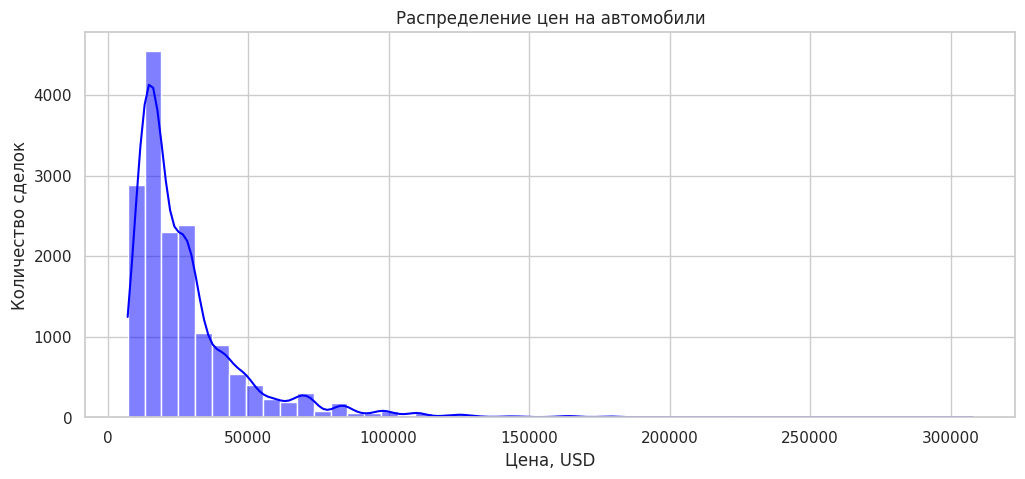

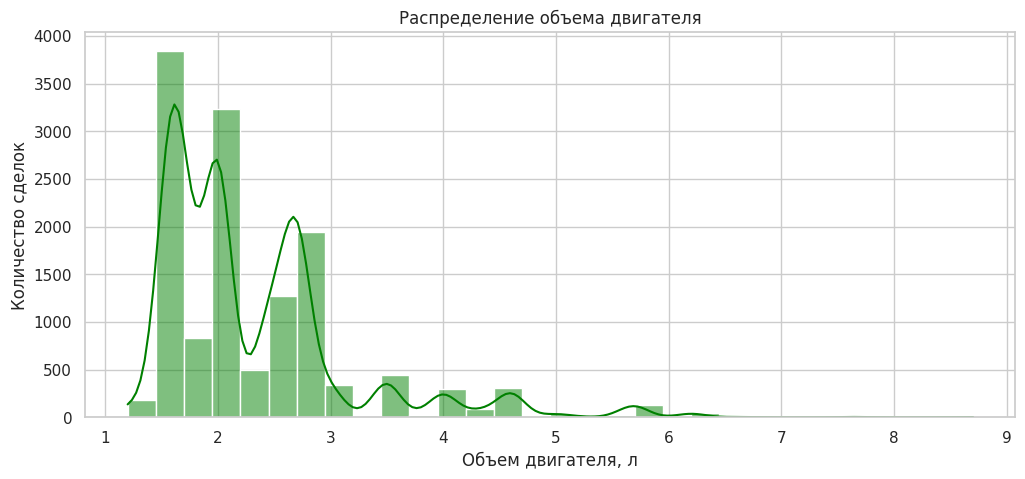

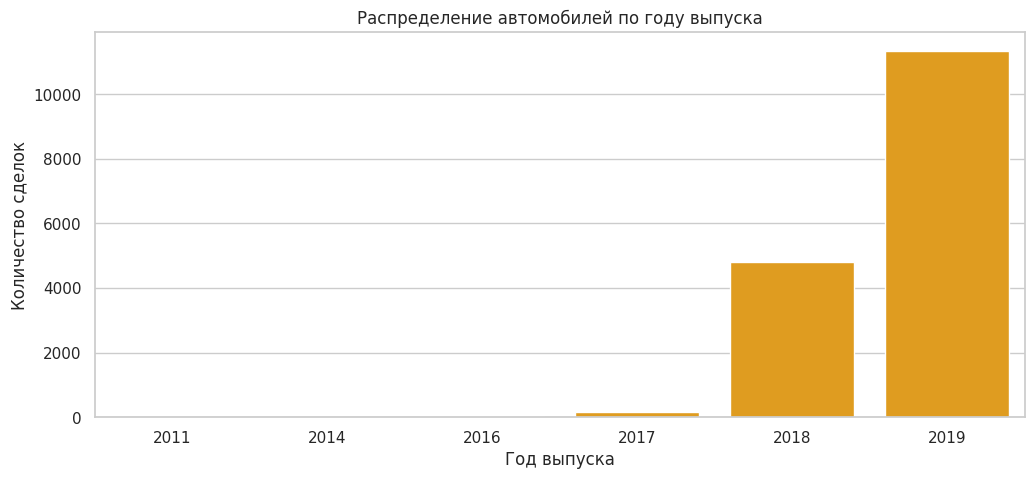

In [ ]:
# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

# 1. Гистограмма распределения цен
plt.figure()
sns.histplot(df['price_usd'], bins=50, kde=True, color='blue')
plt.title('Распределение цен на автомобили')
plt.xlabel('Цена, USD')
plt.ylabel('Количество сделок')
plt.show()

# 2. Гистограмма распределения объема двигателя
plt.figure()
sns.histplot(df['engine_volume'].dropna(), bins=30, kde=True, color='green')
plt.title('Распределение объема двигателя')
plt.xlabel('Объем двигателя, л')
plt.ylabel('Количество сделок')
plt.show()

# 3. Гистограмма распределения года выпуска
plt.figure()
sns.countplot(data=df, x='production_year', color='orange')
plt.title('Распределение автомобилей по году выпуска')
plt.xlabel('Год выпуска')
plt.ylabel('Количество сделок')
plt.show()

### 3.1. Распределение числовых переменных

На основе построенных гистограмм можно зафиксировать следующие факты:

- **Цены на автомобили:** Распределение имеет правостороннюю асимметрию. Основная масса сделок (более 50%) приходится на диапазон до 50 000 USD. Пик продаж находится в сегменте 10 000 - 20 000 USD. Присутствует небольшая доля автомобилей дороже 150 000 USD, формирующая длинный хвост.
- **Объем двигателя:** Распределение мультимодальное (имеет несколько пиков). Наиболее популярны двигатели объемом 1.6 - 1.8 л и 2.0 - 2.2 л. Также заметен сегмент 2.5 - 2.8 л. Автомобили с объемом более 5 литров встречаются крайне редко.
- **Год выпуска:** Рынок представлен преимущественно автомобилями 2019 года выпуска (более 11 000 сделок). Автомобили 2018 года занимают второе место по популярности (около 4 500 сделок). Модели 2017 года и старше представлены единичными продажами, что соответствует фокусу датасета на продажах новых автомобилей за 2019 год.

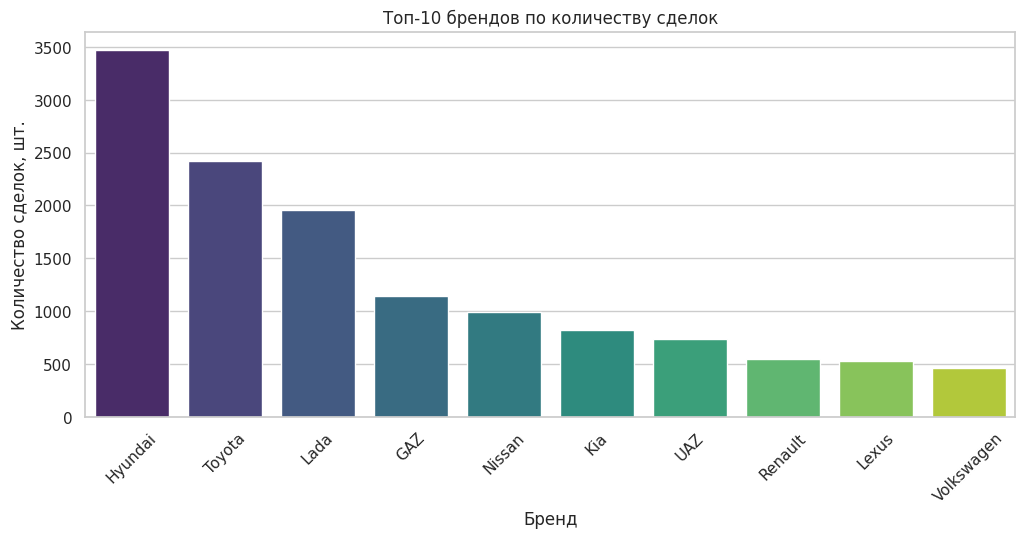

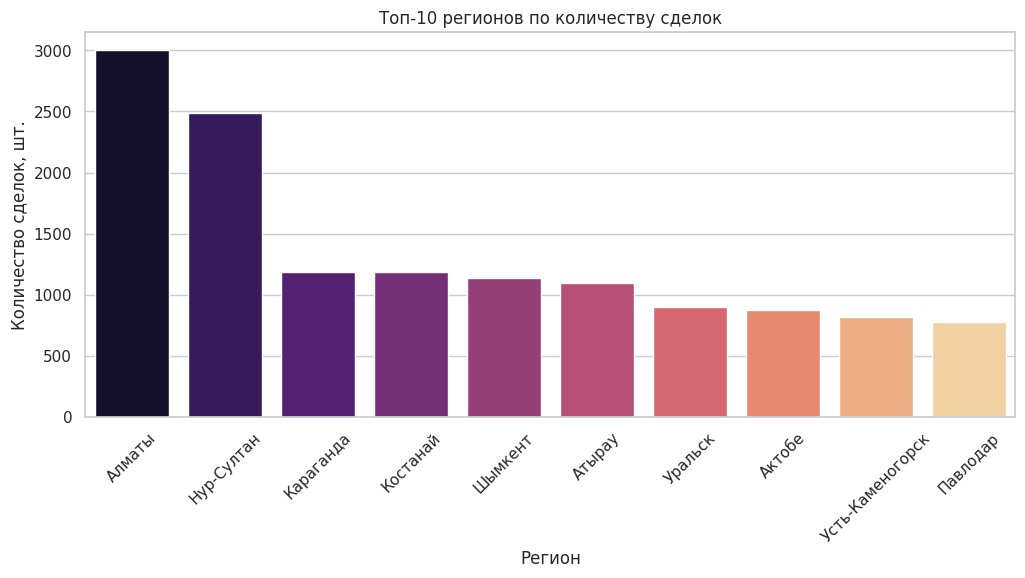

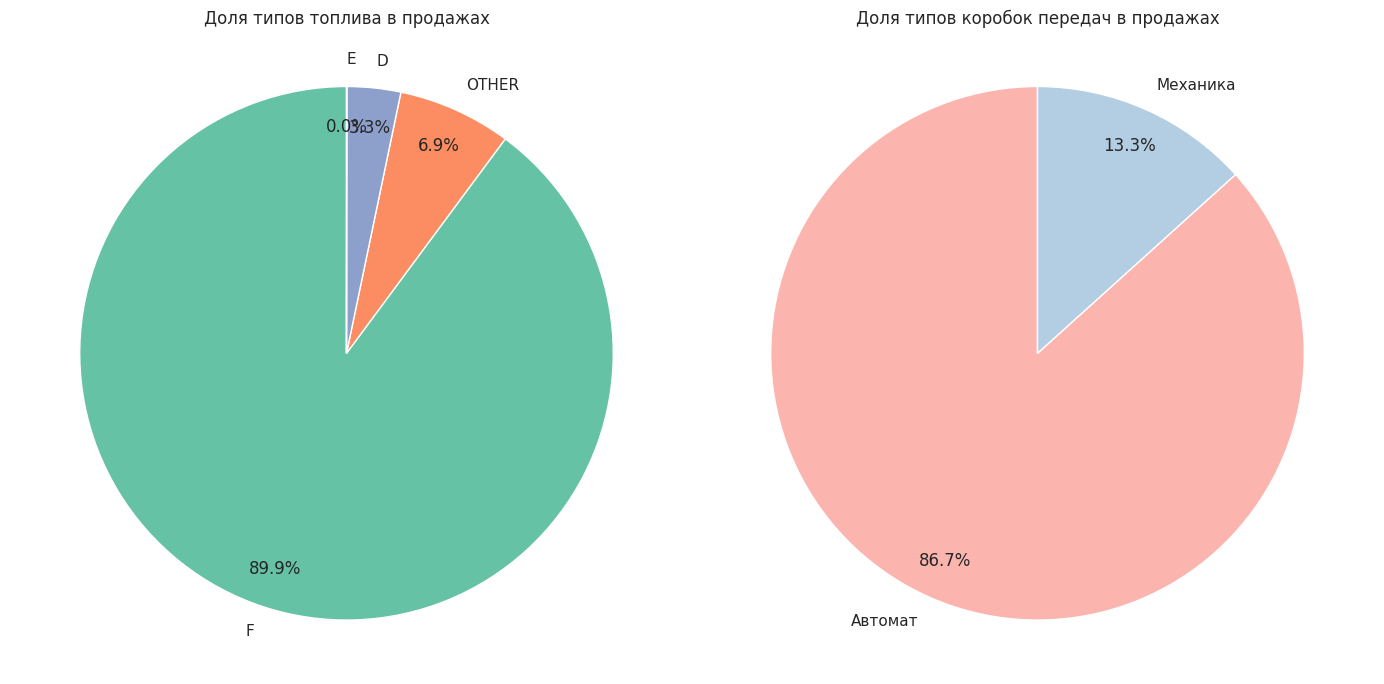

In [ ]:
# Настройка стиля
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

# 1. Топ-10 брендов
plt.figure()
top_brands = df['brand'].value_counts().head(10).reset_index()
top_brands.columns = ['brand', 'count']
sns.barplot(data=top_brands, x='brand', y='count', hue='brand', palette='viridis', legend=False)
plt.title('Топ-10 брендов по количеству сделок')
plt.xlabel('Бренд')
plt.ylabel('Количество сделок, шт.')
plt.xticks(rotation=45)
plt.show()

# 2. Топ-10 регионов
plt.figure()
top_regions = df['region'].value_counts().head(10).reset_index()
top_regions.columns = ['region', 'count']
sns.barplot(data=top_regions, x='region', y='count', hue='region', palette='magma', legend=False)
plt.title('Топ-10 регионов по количеству сделок')
plt.xlabel('Регион')
plt.ylabel('Количество сделок, шт.')
plt.xticks(rotation=45)
plt.show()

# Настраиваем фигуру для круговых диаграмм: 1 строка, 2 колонки
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# 3. Диаграмма по топливу
fuel_counts = df['fuel_type'].value_counts()
axes[0].pie(fuel_counts,
            labels=fuel_counts.index,
            autopct='%1.1f%%',
            startangle=90,
            colors=sns.color_palette('Set2'),
            pctdistance=0.85, # расстояние для процентов
            labeldistance=1.1) # расстояние для подписей
axes[0].set_title('Доля типов топлива в продажах')
axes[0].axis('equal') # чтобы круг был круглым

# 4. Диаграмма по коробкам передач
trans_counts = df['transmission'].value_counts()
axes[1].pie(trans_counts,
            labels=trans_counts.index,
            autopct='%1.1f%%',
            startangle=90,
            colors=sns.color_palette('Pastel1'),
            pctdistance=0.85,
            labeldistance=1.1)
axes[1].set_title('Доля типов коробок передач в продажах')
axes[1].axis('equal')

plt.tight_layout() # чтобы графики не наезжали друг на друга
plt.show()

### 3.2. Продажи по брендам, регионам, топливу и коробкам передач

На основе анализа диаграмм зафиксированы следующие факты:

- **Бренды:** Лидером по количеству сделок является **Hyundai** (около 3500 сделок). На втором месте **Toyota** (около 2400), на третьем **Lada** (около 1950). Далее следуют GAZ, Nissan, Kia, UAZ, Renault, Lexus и Volkswagen. В топ-10 входят как массовые, так и премиальные бренды.
- **Регионы:** Наибольшее количество сделок приходится на **Алматы** (около 3000) и **Нур-Султан** (около 2500). Остальные регионы (Караганда, Костанай, Шымкент, Атырау, Уральск, Актобе, Усть-Каменогорск, Павлодар) имеют значительно меньшие объемы (от 700 до 1200 сделок).
- **Топливо:** Абсолютное большинство продаж приходится на бензиновые автомобили (**F** - около 90%). Дизель (**D**) занимает около 3%, а на категорию **OTHER** (пропуски или другие виды) приходится около 7%. Электро и гибриды в данных практически отсутствуют.
- **Коробка передач:** Доминируют автомобили с автоматической коробкой передач (**Автомат** - около 87%). На механику (**Механика**) приходится около 13% сделок.

Коэффициент корреляции между ценой и объемом двигателя (Пирсон): 0.708


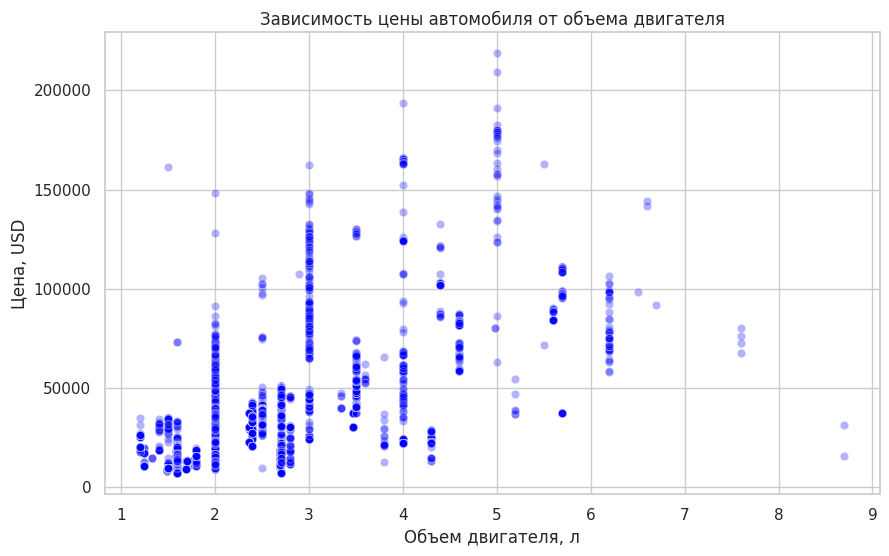

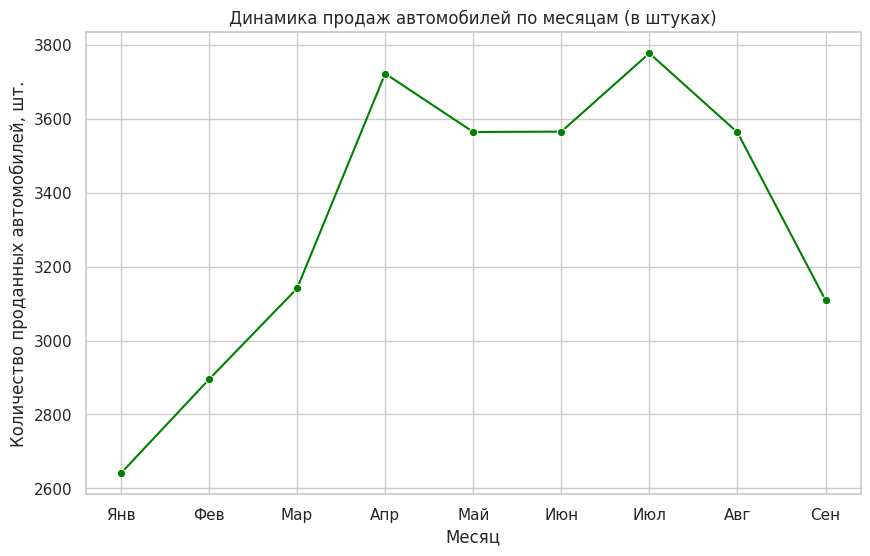

In [ ]:
# 1. Считаем коэффициент корреляции Пирсона между ценой и объемом двигателя
corr_price_volume = df[['price_usd', 'engine_volume']].dropna().corr(method='pearson').iloc[0, 1]
print(f"Коэффициент корреляции между ценой и объемом двигателя (Пирсон): {corr_price_volume:.3f}")

# 2. Строим диаграмму рассеяния (scatter plot)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='engine_volume', y='price_usd', alpha=0.3, color='blue')
plt.title('Зависимость цены автомобиля от объема двигателя')
plt.xlabel('Объем двигателя, л')
plt.ylabel('Цена, USD')
plt.show()

# 3. Смотрим на продажи по месяцам (динамика)
df['month_num'] = df['date'].dt.month
monthly_sales = df.groupby('month_num').agg(
    total_sales=('sales_usd', 'sum'),
    count_sales=('quantity', 'sum')
).reset_index()

# Переводим номер месяца в название для графика
month_names = {1: 'Янв', 2: 'Фев', 3: 'Мар', 4: 'Апр', 5: 'Май', 6: 'Июн',
               7: 'Июл', 8: 'Авг', 9: 'Сен', 10: 'Окт', 11: 'Ноя', 12: 'Дек'}
monthly_sales['month_name'] = monthly_sales['month_num'].map(month_names)

# Строим график динамики по месяцам (в штуках)
plt.figure(figsize=(10, 6))
sns.lineplot(data=monthly_sales, x='month_name', y='count_sales', marker='o', color='green')
plt.title('Динамика продаж автомобилей по месяцам (в штуках)')
plt.xlabel('Месяц')
plt.ylabel('Количество проданных автомобилей, шт.')
plt.show()

### 3.3. Связи между признаками и динамика продаж

На этом этапе мы проверили наличие связей между числовыми признаками и посмотрели на динамику продаж.

**Цена и объем двигателя:**
- Коэффициент корреляции Пирсона составляет **0.708**, что указывает на сильную положительную связь. Факт: с увеличением объема двигателя цена автомобиля, как правило, растет.
- На диаграмме рассеяния видно, что при объеме двигателя 1.0 - 2.0 л разброс цен относительно невелик (в основном до 50 000 USD). При объеме 4.0 - 5.0 л разброс цен значительно шире (от 50 000 до 200 000+ USD).

**Динамика продаж по месяцам:**
- В датасете представлены данные за период с января по сентябрь 2019 года.
- Наблюдается рост продаж с января (около 2650 сделок) по апрель (около 3700 сделок).
- В мае-июне наступает небольшое плато, после чего в **июле** фиксируется пик продаж (почти 3800 сделок).
- В августе и сентябре наблюдается спад (к сентябрю до 3100 сделок).

<a id="market"></a>
## 4. Анализ рынка и позиции Mercur Auto

In [ ]:
# 1. Считаем показатели
total_market_quantity = df['quantity'].sum()
total_market_sales = df['sales_usd'].sum()
mercur_df = df[df['company'] == 'Mercur Auto']
mercur_quantity = mercur_df['quantity'].sum()
mercur_sales = mercur_df['sales_usd'].sum()

share_quantity = (mercur_quantity / total_market_quantity) * 100
share_sales = (mercur_sales / total_market_sales) * 100
avg_check_market = total_market_sales / total_market_quantity
avg_check_mercur = mercur_sales / mercur_quantity

# 2. Собираем основную таблицу (без строк 3 и 4)
summary_data = {
    'Показатель': [
        'Продажи, шт.',
        'Выручка, USD',
        'Средний чек, USD'
    ],
    'Рынок': [
        total_market_quantity,
        total_market_sales,
        avg_check_market
    ],
    'Mercur Auto': [
        mercur_quantity,
        mercur_sales,
        avg_check_mercur
    ],
    'Доля Mercur Auto': [
        f"{share_quantity:.2f}%",
        f"{share_sales:.2f}%",
        f"выше рынка на {(avg_check_mercur / avg_check_market - 1) * 100:.1f}%"
    ]
}

summary_df = pd.DataFrame(summary_data)

# Форматируем таблицу
display(summary_df.style.format({
    'Рынок': lambda x: f"{x:,.0f}" if isinstance(x, (int, float)) else x,
    'Mercur Auto': lambda x: f"{x:,.0f}" if isinstance(x, (int, float)) else x
}))

# 3. Топ-5 брендов Mercur Auto по выручке (сравнение с рынком)
# Считаем выручку по брендам для Mercur и для всего рынка
mercur_brands = mercur_df.groupby('brand', observed=True)['sales_usd'].sum().sort_values(ascending=False)
market_brands = df.groupby('brand', observed=True)['sales_usd'].sum()

# Собираем данные в таблицу (все бренды Mercur)
top_brands_df = pd.DataFrame({
    'Бренд': mercur_brands.index,
    'Выручка Mercur, USD': mercur_brands.values,
    'Выручка рынка, USD': market_brands.loc[mercur_brands.index].values
})
top_brands_df['Доля Mercur в выручке бренда, %'] = (top_brands_df['Выручка Mercur, USD'] / top_brands_df['Выручка рынка, USD']) * 100

# Форматируем и выводим
print("\nБренды Mercur Auto по выручке (сравнение с рынком):")
display(top_brands_df.style.format({
    'Выручка Mercur, USD': '{:,.0f}',
    'Выручка рынка, USD': '{:,.0f}',
    'Доля Mercur в выручке бренда, %': '{:.2f}%'
}))

,Показатель,Рынок,Mercur Auto,Доля Mercur Auto
0,"Продажи, шт.","29,977",376,1.25%
1,"Выручка, USD","653,691,982","14,712,569",2.25%
2,"Средний чек, USD","21,806","39,129",выше рынка на 79.4%



Бренды Mercur Auto по выручке (сравнение с рынком):


,Бренд,"Выручка Mercur, USD","Выручка рынка, USD","Доля Mercur в выручке бренда, %"
0,Volkswagen,"6,013,297","21,106,708",28.49%
1,Porsche,"5,113,513","5,113,513",100.00%
2,Audi,"3,585,759","3,585,759",100.00%


### 4.1. Доля рынка и позиционирование Mercur Auto

На основе расчетов зафиксированы следующие факты:

- **Доля рынка:** Mercur Auto занимает **1.25%** рынка в штуках (376 из 29 977 проданных авто) и **2.25%** в деньгах (14.7 млн USD из 653.7 млн USD общей выручки).
- **Средний чек:** Средний чек компании составляет **39 129 USD**, что **на 79.4% выше** среднего чека по рынку (21 806 USD). Это указывает на позиционирование в премиальном сегменте.
- **Структура продаж:** Портфель брендов Mercur Auto состоит всего из трех марок: **Volkswagen** (6.0 млн USD), **Porsche** (5.1 млн USD) и **Audi** (3.6 млн USD). При этом по Porsche и Audi компания занимает **100% рынка** (в данных это единственный дилер, продающий эти бренды). По Volkswagen доля компании в общей выручке бренда на рынке составляет **28.49%**. Столь высокая доля в деньгах при низкой доле в штуках объясняется премиальным позиционированием. Компания продает меньше машин, но по более высокой цене.

In [ ]:
# 1. Считаем статистику по компаниям
company_stats = df.groupby('company', observed=True).agg(
    total_quantity=('quantity', 'sum'),
    total_sales=('sales_usd', 'sum')
).reset_index()
company_stats['avg_check'] = company_stats['total_sales'] / company_stats['total_quantity']

# 2. Исключаем компании, которые по названию относятся к грузовому/автобусному сегменту
# (даже если у них остались легковые записи, их бизнес-профиль не совпадает с Mercur Auto)
exclude_keywords = ['Bus', 'КАМАЗ', 'Hino', 'Truck', 'Автобус', 'Груз']
mask_exclude = company_stats['company'].str.contains('|'.join(exclude_keywords), case=False, na=False)
company_stats_clean = company_stats[~mask_exclude].copy()

print(f"Исключено компаний по названию: {mask_exclude.sum()}")

# 3. Выводим топ-15 компаний по среднему чеку (после исключения)
top_companies = company_stats_clean.sort_values('avg_check', ascending=False).head(15)

print("\nТоп-15 компаний по среднему чеку (без грузовых/автобусных):")
display(top_companies.style.format({
    'total_quantity': '{:,.0f}',
    'total_sales': '{:,.0f}',
    'avg_check': '{:,.0f}'
}))

Исключено компаний по названию: 3

Топ-15 компаний по среднему чеку (без грузовых/автобусных):


,company,total_quantity,total_sales,avg_check
20,Автокапитал,33,"3,402,682","103,112"
1,Almaty Motors Premium,95,"9,479,733","99,787"
16,TERRA MOTORS,58,"5,691,050","98,122"
4,Autokapital,112,"10,783,346","96,280"
7,Eurasia Motor Premium,57,"4,319,952","75,789"
23,Автоцентр-Бавария,453,"29,174,309","64,402"
14,Scandinavian Motors,40,"2,530,529","63,263"
35,Хино Моторс Казахстан,51,"2,300,556","45,109"
17,Toyota Motor Kazakhstan,"2,952","132,545,269","44,900"
10,Mercur Auto,376,"14,712,569","39,129"


In [ ]:
# Находим все компании, которые продают Volkswagen (кроме Mercur Auto)
vw_companies = df[(df['brand'] == 'Volkswagen') & (df['company'] != 'Mercur Auto')]

# Считаем статистику по ним
vw_stats = vw_companies.groupby('company', observed=True).agg(
    total_quantity=('quantity', 'sum'),
    total_sales=('sales_usd', 'sum')
).reset_index()
vw_stats['avg_check'] = vw_stats['total_sales'] / vw_stats['total_quantity']

# Сортируем по выручке
vw_stats = vw_stats.sort_values('total_sales', ascending=False)

print("Другие компании, продающие Volkswagen:")
display(vw_stats.style.format({
    'total_quantity': '{:,.0f}',
    'total_sales': '{:,.0f}',
    'avg_check': '{:,.0f}'
}))

Другие компании, продающие Volkswagen:


,company,total_quantity,total_sales,avg_check
0,Volkswagen Group Rus,651,"13,176,454","20,240"
1,Автодом Motors KST,46,"936,366","20,356"
2,Автомир-Центр,34,"660,553","19,428"
3,"ТОО ""Eurasia Motor Zhaik""",15,"320,038","21,336"


### 4.2. Ближайшие конкуренты Mercur Auto

Для определения конкурентов мы проанализировали средний чек по всем компаниям на рынке и исключили те, чей бизнес-профиль явно относится к грузовому или автобусному сегменту (по названию).

**Факты:**
- **По брендам Porsche и Audi** в датасете нет других дилеров. Mercur Auto является единственным продавцом этих марок.
- **По бренду Volkswagen** конкуренты есть, но они работают в другом ценовом сегменте:
    - `Volkswagen Group Rus` продает 651 автомобиль со средним чеком **20 240 USD** (массовый сегмент).
    - `Автодом Motors KST`, `Автомир-Центр`, `Eurasia Motor Zhaik` также имеют средний чек около 20 000 USD.
    - Средний чек Mercur Auto по всем брендам составляет **39 129 USD**, что значительно выше, чем у конкурентов по Volkswagen.
- **Ближайшими по среднему чеку** (в диапазоне 30 000 - 45 000 USD) являются:
    - `Toyota Motor Kazakhstan` (44 900 USD, 2952 сделки).
    - `ММС Рус` (33 721 USD, 420 сделок).
    - `Subaru Kazakhstan` (32 448 USD, 264 сделки).

 Mercur Auto не имеет прямых конкурентов в премиум-сегменте по своим брендам. Однако компания может конкурировать с дилерами Toyota, Subaru и ММС за клиентов, готовых потратить 30-40 тыс. USD.

<a id="conclusions"></a>
## 5. Выводы и рекомендации

### 5.1. Сильные стороны Mercur Auto

- **Премиальное позиционирование:** Средний чек компании составляет 39 129 USD, что на 79.4% выше среднего чека по рынку (21 806 USD). Это позволяет компании получать более высокую выручку с каждой сделки.
- **Уникальность портфеля брендов:** Mercur Auto является единственным дилером Porsche и Audi в представленных данных. По этим маркам у компании нет прямых конкурентов.
- **Эффективность по выручке:** Доля компании в деньгах (2.25%) почти в два раза превышает долю в штуках (1.25%). Это подтверждает, что компания продает меньше машин, но по более высокой цене.

### 5.2. Слабые стороны и риски Mercur Auto

- **Низкая доля рынка в штуках:** Компания занимает всего 1.25% рынка по количеству проданных автомобилей. Это ограничивает ее влияние на рынок и делает уязвимой к колебаниям спроса.
- **Узкий портфель брендов:** Компания работает всего с тремя брендами (Volkswagen, Porsche, Audi). Это создает риск зависимости от спроса на эти конкретные марки. Если спрос на один из брендов упадет, это сильно скажется на выручке.
- **Конкуренция в сегменте Volkswagen:** Хотя по Porsche и Audi конкурентов нет, по Volkswagen компания конкурирует с крупными игроками (Volkswagen Group Rus), которые продают больше машин по более низким ценам.

### 5.3. Рекомендации

1.  **Укреплять премиальное позиционирование:** Продолжать делать ставку на Porsche и Audi, так как это уникальные бренды в данных, и они приносят высокую выручку.
2.  **Диверсифицировать портфель брендов:** Рассмотреть возможность добавления еще одного премиального или люксового бренда, чтобы снизить зависимость от трех текущих марок.
3.  **Развивать направление Volkswagen в премиум-сегменте:** Учитывая, что конкуренты продают Volkswagen в массовом сегменте (средний чек ~20 000 USD), Mercur Auto может сфокусироваться на дорогих комплектациях и кроссоверах, чтобы удерживать высокий средний чек.
4.  **Анализировать сезонность:** Учитывая пик продаж в июле и спад в сентябре, рекомендуется адаптировать маркетинговые акции под эти периоды.

### 5.4. Ограничения исследования

- **Неполный год:** Данные представлены только за период с января по сентябрь 2019 года. Это не позволяет оценить полную годовую динамику и сезонность.
- **Отсутствие данных о прямых конкурентах:** В датасете нет других дилеров, продающих Porsche и Audi, что может быть связано с особенностями выгрузки данных, а не с реальной рыночной ситуацией.
- **Гипотезы, требующие проверки:**
    - Причины пика продаж в июле (сезонность или акции) требуют дополнительного анализа.
    - Влияние премиального позиционирования на выбор клиентов (готовы ли они платить больше за те же бренды у Mercur Auto) требует опроса или анализа цен конкурентов.

In [ ]:
# 1. Проверка: сумма долей по брендам (в штуках) должна быть 100%
brand_shares = df['brand'].value_counts(normalize=True) * 100
print(f"Сумма долей по брендам (в штуках): {brand_shares.sum():.2f}%")

# 2. Проверка: сумма выручки по компаниям должна равняться общей выручке рынка
total_sales_check = df.groupby('company', observed=True)['sales_usd'].sum().sum()
print(f"Сумма выручки по компаниям: {total_sales_check:,.2f} USD")
print(f"Общая выручка рынка: {df['sales_usd'].sum():,.2f} USD")
print(f"Разница: {total_sales_check - df['sales_usd'].sum():.2f} USD")

# 3. Проверка: количество строк и уникальных компаний
print(f"\nВсего строк: {len(df)}")
print(f"Уникальных компаний: {df['company'].nunique()}")

Сумма долей по брендам (в штуках): 100.00%
Сумма выручки по компаниям: 653,691,981.79 USD
Общая выручка рынка: 653,691,981.79 USD
Разница: -0.00 USD

Всего строк: 16353
Уникальных компаний: 36
